InstanceNumber metadata present in all files: True

MRI shape:
(256, 256, 256)

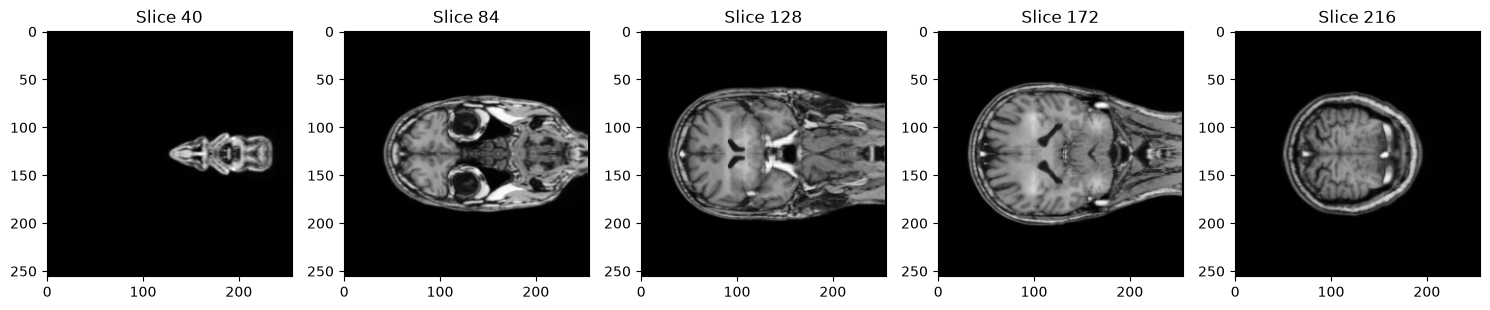

In [ ]:
import pydicom # Handling dicom
import numpy as np # Tensors
import matplotlib.pyplot as plt # Plotting
import os # File system
from rich import print # Logging (I like coloered output)

# Input data as provided
DATA_DIR = "data/Aneurysm_MRI"
# Retrieving all filenames
dicom_files = [f for f in os.listdir(DATA_DIR) if f.lower().endswith('.dcm')]
dicom_files.sort()

# Loading each slice with dcmread in list
slices = [pydicom.dcmread(os.path.join(DATA_DIR, f)) for f in dicom_files]
# Do all .dcm file have an instance number?
slices_have_idx = all([s.InstanceNumber is not None for s in slices])
print(f"InstanceNumber metadata present in all files: {slices_have_idx}")

# Reordering based on slice idx
if slices_have_idx:
    slices.sort(key=lambda s: int(s.InstanceNumber)) # metadata is string

# List to tensor (accessign pixel_array key)
vol3d = np.stack([s.pixel_array for s in slices], axis=2) # Stacking as (row,col,slice)
D,H,W = vol3d.shape # Depth - height - width
print("MRI shape:", vol3d.shape) 

# Plotting 5 slices evenly spaced from 40 to D-40 (first and last are all zeros)
FIRST_SLICE, LAST_SLICE = 40, D-40
plt.figure(figsize=(15,3))
for pltidx, sliceidx in enumerate(np.linspace(FIRST_SLICE, LAST_SLICE, 5).astype(int)):
    plt.subplot(1,5,pltidx+1)
    plt.imshow(vol3d[sliceidx-1], cmap='gray')
    plt.title(f"Slice {sliceidx}")
plt.tight_layout()
plt.show()



In [30]:
# ImageOrientationPatient: checking that it is unique in all slices 
set_of_unique_orientations = np.unique(np.array([s.ImageOrientationPatient for s in slices]), axis=0)
if len(set_of_unique_orientations) == 1:
    print("Orientation UNIFORM")
else:
    print("Slices have different orientations")

set_of_unique_spacings = np.unique(np.array([s.PixelSpacing for s in slices]), axis=0)
if len(set_of_unique_orientations) == 1:
    print("Spacing UNIFORM")
else:
    print("Slices have different Spacings")

set_of_unique_thicknesses= np.unique([s.SliceThickness for s in slices])


image_orientation_patient = slices[0].ImageOrientationPatient
X_dir,Y_dir = np.array(image_orientation_patient[:3],float), np.array(image_orientation_patient[3:6],float)
Z_dir = np.cross(X_dir, Y_dir) # Right-handed, computing Z direction
pixel_spacing_X = float(slices[0].PixelSpacing[0])
pixel_spacing_Y = float(slices[0].PixelSpacing[1])


Orientation UNIFORM

Spacing UNIFORM

In [48]:
# Initializing volume 2 patient matrix as identity
vol2pat = np.eye(4)
# First col: moving down a row (row index) follows Y_dir (IOP[3:6]) * row spacing
vol2pat[:3,0] = Y_dir * pixel_spacing_Y
# Second col: moving along a row (column index) follows X_dir (IOP[0:3]) * column spacing
vol2pat[:3,1] = X_dir * pixel_spacing_X

# Third colums, slice spacings: computed from slice positions
imagepos_firstslice = np.array(slices[0].ImagePositionPatient, float)
imagepos_lastslice = np.array(slices[-1].ImagePositionPatient, float)
vol2pat[:3,2] = (imagepos_lastslice - imagepos_firstslice) / (len(slices) - 1)

# Fourth column transformss origin to imageposition for first slice
vol2pat[:3,3] = imagepos_firstslice
print("vol2pat:")
print(vol2pat)

# Sanity check: voxel (0,0,k) must land on slice k's ImagePositionPatient
for k in (0, 1, len(slices) - 1):
    assert np.allclose(vol2pat @ [0, 0, k, 1], [*np.array(slices[k].ImagePositionPatient, float), 1])

vol2pat:

[[ 0. -1.  0.  0.]
 [ 1.  0.  0.  0.]
 [ 0.  0. -1.  0.]
 [ 0.  0.  0.  1.]]

In [55]:
# Identifying the anatomical orientation
from numpy import negative

def anatomical_orientation(vol2pat):
    # Positive-Negative axis have this labels, will be appended to the string based on the axis dirs found
    positive_labels = {0:'L',1:'P',2:'S'}
    negative_labels = {0:'R',1:'A',2:'I'}
    anatomical_orientation = ""

    for colidx, column in enumerate(vol2pat.T[:3]):
        main_axis = np.argmax(np.abs(column[:3])) # What row in each column has the max absoute value? (most of axis direction is aligned here)
        # Appending the label dependin on axis dir
        is_val_positive = column[main_axis] > 0
        anatomical_orientation += positive_labels[main_axis] if is_val_positive else negative_labels[main_axis]
    return anatomical_orientation
print(f"Anatomical orientation: {anatomical_orientation(vol2pat)}")

Anatomical orientation: PRI

In [ ]:
# Transforming PRI to RPI -> Must swap the first two axes

# First create the transform that represents the RPI reference frame ()
rpi_rf = np.array([[-1,0, 0,0],
                [0, 1, 0,0],
                [0, 0,-1,0],
                [0, 0, 0, 1]])
# Then I instantiate the PRI reference directions (vol2pat rotation part)
pri_rf = np.eye(4)
pri_rf[:3,:3] = vol2pat[:3,:3]

# Computing the relative transform from PRI to RPI
pri_to_rpi = np.linalg.inv(pri_rf) @ rpi_rf
# Chaining to the vol2pat transform: -> Volume-to-PRI-to-RPI
vol2pat_rpi = vol2pat @ pri_to_rpi
# Checking the mat columns
print("Anatomical orientation after transformation: ", anatomical_orientation(vol2pat_rpi))

Anatomical orientation after transformation:  RPI